# 2.0 — Binning Workbench: estimate, persist & hand-tune the WoE bins

**Goal**: turn binning into a *first-class, hand-tunable artifact*. This notebook estimates an
initial binning for every candidate variable, **persists it to `references/bin_spec.yaml`**
(git-tracked, the single source of truth for 2.1 and every downstream notebook), then shows the
per-bin WoE table and plots **WoE pooled** and **WoE over SAFRA on the same bins** so you can
manually merge adjacent bins until each variable is *stable across vintages* **and**
*discriminating*.

**Input**: `data/interim/applications.parquet` (validated in 1.1). All signal is measured on the
labeled `Contratado` sample — the **selection-bias caveat applies to every number here**.

**The tuning loop** (see §7): edit `references/bin_spec.yaml` by hand — delete a value from a
numeric `cuts` list to merge two adjacent bins, or join two categories into one `groups` list —
then re-run §3–§6. The estimate/write step (§2) is **guarded** so re-running never clobbers your
edits.

**Conventions**: WoE = `ln(%goods/%bads)`, **positive = safer**; 0.5 smoothing; explicit
`(missing)` bin (NaN = no snapshot / no open-finance consent) and `(outros)` (categories not
listed in any group) everywhere, so IV includes them. Machinery: `credit_policy.woe` /
`credit_policy.binning`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))
from credit_policy import woe, binning          # noqa: E402  (path set above)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

APP_PATH = PROJECT_DIR / "data" / "interim" / "applications.parquet"
BIN_SPEC_PATH = PROJECT_DIR / "references" / "bin_spec.yaml"

COLOR_POS, COLOR_NEG, COLOR_MISS = "steelblue", "indianred", "0.55"

# Set True to (re)generate bin_spec.yaml from quantiles. WARNING: discards manual edits.
REESTIMATE = False

## 1. Load & candidates

Labeled `Contratado` sample and the eight candidate variables (four numeric, four categorical).
Binary flags are trivial and stay out of the spec (they are handled inline in 2.1).

In [2]:
app = pd.read_parquet(APP_PATH)
lab = app[app["OVER30M2"].notna()].copy()
y = lab["OVER30M2"].astype(int)

NUM_VARS = ["score_klavi_1", "score_klavi_2", "Renda", "Capacidade Financeira"]
CAT_VARS = ["classe_social", "status_empregaticio", "regiao", "risco_aposta"]
CAND_VARS = NUM_VARS + CAT_VARS

print(f"labeled sample: {len(lab):,} applications  |  bads: {y.sum():,}  |  default rate: {y.mean():.2%}")
print(f"safras: {lab['SAFRA'].min()}–{lab['SAFRA'].max()}  |  labeled rows per safra: "
      f"{lab.groupby('SAFRA').size().min():,}–{lab.groupby('SAFRA').size().max():,}")
lab[CAND_VARS].notna().mean().mul(100).round(1).rename("coverage_pct").to_frame()

labeled sample: 24,148 applications  |  bads: 2,488  |  default rate: 10.30%
safras: 202406–202506  |  labeled rows per safra: 1,417–2,367


,coverage_pct
score_klavi_1,4.1
score_klavi_2,45.9
Renda,4.5
Capacidade Financeira,45.6
classe_social,51.5
status_empregaticio,51.0
regiao,51.4
risco_aposta,4.5


## 2. Estimate & persist the initial spec (guarded)

`estimate_spec` gives adaptive quantile cuts for numerics (interior cut points, rounded) and one
group per non-rare category for categoricals. It is written **only if the file is missing or
`REESTIMATE=True`**, so the manual tuning in §7 is safe across re-runs.

In [3]:
if REESTIMATE or not BIN_SPEC_PATH.exists():
    spec0 = binning.estimate_spec(lab, NUM_VARS, CAT_VARS)
    binning.save_spec(spec0, BIN_SPEC_PATH)
    print(f"wrote initial spec -> {BIN_SPEC_PATH.relative_to(PROJECT_DIR)}")
else:
    print(f"kept existing spec at {BIN_SPEC_PATH.relative_to(PROJECT_DIR)} "
          f"(set REESTIMATE=True to regenerate from quantiles)")

kept existing spec at references/bin_spec.yaml (set REESTIMATE=True to regenerate from quantiles)


## 3. Load spec & apply

Load the (possibly hand-edited) spec and bin the sample once into `binned`. This cell is separate
from §2 on purpose: the tuning loop re-runs §3–§6 only, never the write in §2.

In [4]:
spec = binning.load_spec(BIN_SPEC_PATH)
binned = binning.transform(lab, spec)

bin_summary = pd.DataFrame([
    {"variable": v, "type": spec[v]["type"],
     "n_bins": int((woe.woe_table(binned[v], y)["n"] > 0).sum()),
     "IV": woe.iv_of(woe.woe_table(binned[v], y))}
    for v in CAND_VARS
]).sort_values("IV", ascending=False).reset_index(drop=True)
bin_summary["verdict"] = bin_summary["IV"].apply(woe.iv_verdict)
bin_summary.round({"IV": 4})

,variable,type,n_bins,IV,verdict
0,classe_social,categorical,3,0.0890,weak
1,Capacidade Financeira,numeric,5,0.0669,weak
2,score_klavi_2,numeric,5,0.0354,weak
3,status_empregaticio,categorical,4,0.0313,weak
4,regiao,categorical,6,0.0247,weak
5,score_klavi_1,numeric,5,0.0061,useless
6,Renda,numeric,6,0.0061,useless
7,risco_aposta,categorical,9,0.0051,useless


## 4. WoE table — per-bin detail (focus variable)

The full per-bin WoE table for one variable (`FOCUS`) — the precise numbers behind the §5 bars
(n, bad rate, WoE, IV contribution), so merges can be decided exactly rather than by eye. Set
`FOCUS` to any candidate; it defaults to `Capacidade Financeira` (the #2-IV, non-monotone
variable). Re-run this cell after editing `bin_spec.yaml` to read the new bins.

In [5]:
FOCUS = "regiao"      # change to inspect any candidate variable
g_focus = woe.woe_table(binned[FOCUS], y)
print(f"{FOCUS} — IV = {woe.iv_of(g_focus):.4f}  ({woe.iv_verdict(woe.iv_of(g_focus))})")
g_focus.query("n > 0")[["n", "bads", "bad_rate", "pct_goods", "pct_bads", "woe", "iv_contrib"]].round(4)

regiao — IV = 0.0247  (weak)


,n,bads,bad_rate,pct_goods,pct_bads,woe,iv_contrib
bin,,,,,,,
Sudeste,7630,698,0.0915,0.3201,0.2807,0.1312,0.0052
Nordeste,1918,214,0.1116,0.0787,0.0862,-0.0911,0.0007
Centro-Oeste,1103,94,0.0852,0.0466,0.0380,0.2048,0.0018
Norte,928,81,0.0873,0.0391,0.0328,0.1779,0.0011
Sul,836,52,0.0622,0.0362,0.0211,0.5404,0.0082
(missing),11733,1349,0.1150,0.4794,0.5423,-0.1232,0.0077


## 5. WoE geral (pooled) — the shape of risk

WoE per bin on the spec bins, pooled over all safras. Blue = safer than average, red = riskier,
gray = `(missing)`. This is the *discrimination* read: a good binning shows clear, ideally
monotone separation. Merge bins whose WoE is indistinguishable.

In [6]:
# Shortlist frozen in credit_policy.VAR_SELECTION (single source of truth for 2.0/2.1/2.2).
# Panels below are restricted to it; regiao is excluded on fairness grounds.
from credit_policy import VAR_SELECTION

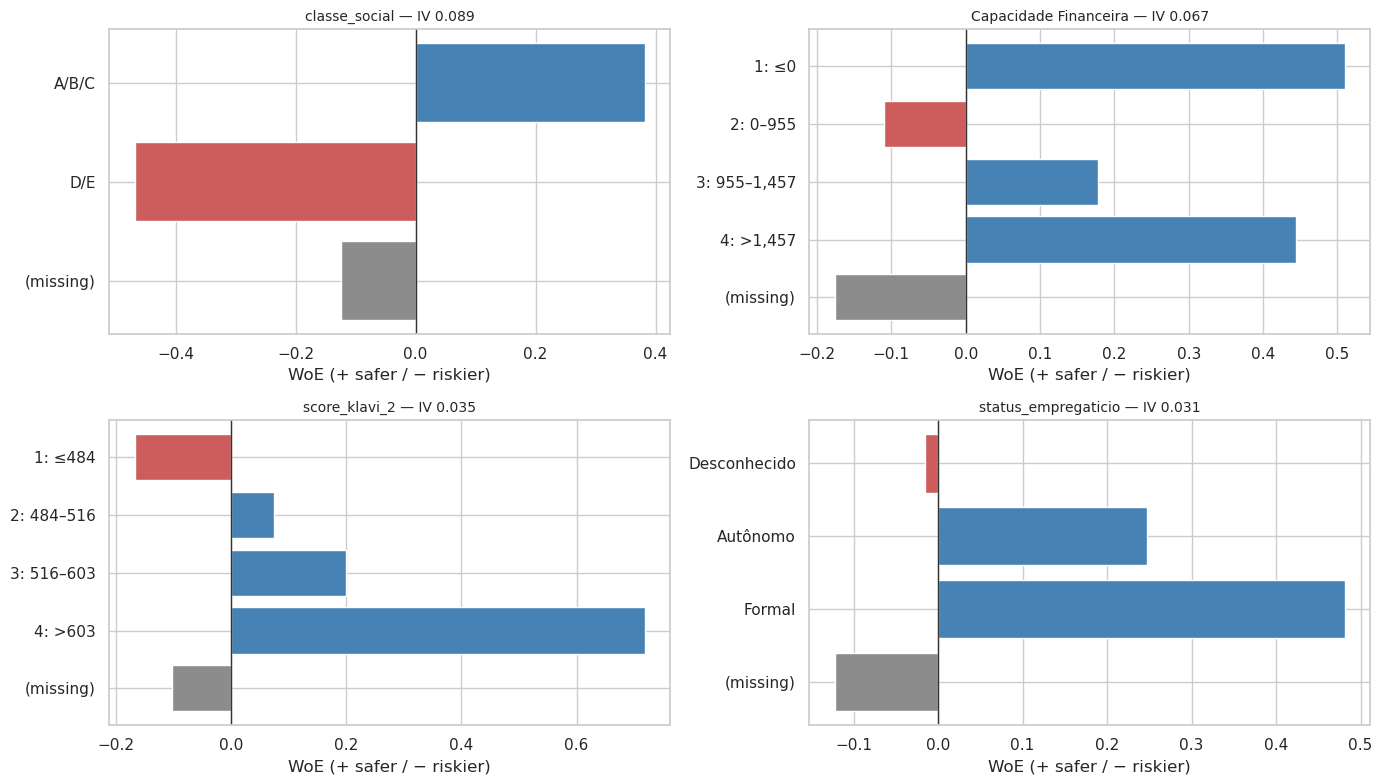

In [7]:
plot_order = bin_summary["variable"].tolist()      # panels ordered by IV (descending)
plot_order = [p for p in plot_order if p in VAR_SELECTION]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))    # landscape, fits a 16:9 slide
for ax, v in zip(axes.flat, plot_order):
    g = woe.woe_table(binned[v], y).query("n > 0")
    labels = g.index.astype(str)
    colors = [COLOR_MISS if b == "(missing)" else (COLOR_POS if w >= 0 else COLOR_NEG)
              for b, w in zip(labels, g["woe"])]
    ax.barh(labels, g["woe"], color=colors)
    ax.axvline(0, color="0.2", lw=1)
    ax.invert_yaxis()
    ax.set_title(f"{v} — IV {woe.iv_of(woe.woe_table(binned[v], y)):.3f}", fontsize=10)
    ax.set_xlabel("WoE (+ safer / − riskier)")
plt.tight_layout()
plt.show()

## 6. WoE por safra — is the binning stable across vintages?

Within each safra, WoE per bin on the **same spec bins** (bins with n < 10 in a safra are masked,
so lines break instead of showing fake points). Numerics: light→dark = low→high bin; `(missing)`
is the gray dashed line. This is the *stability* read: flat, well-separated lines are good;
converging or crossing lines say the bin split is too fine / unstable — merge it. The thin
open-finance variables (`score_klavi_1`, `Renda`, `risco_aposta`) will be mostly masked here
(~4.5% coverage), which is itself the verdict on their usability.

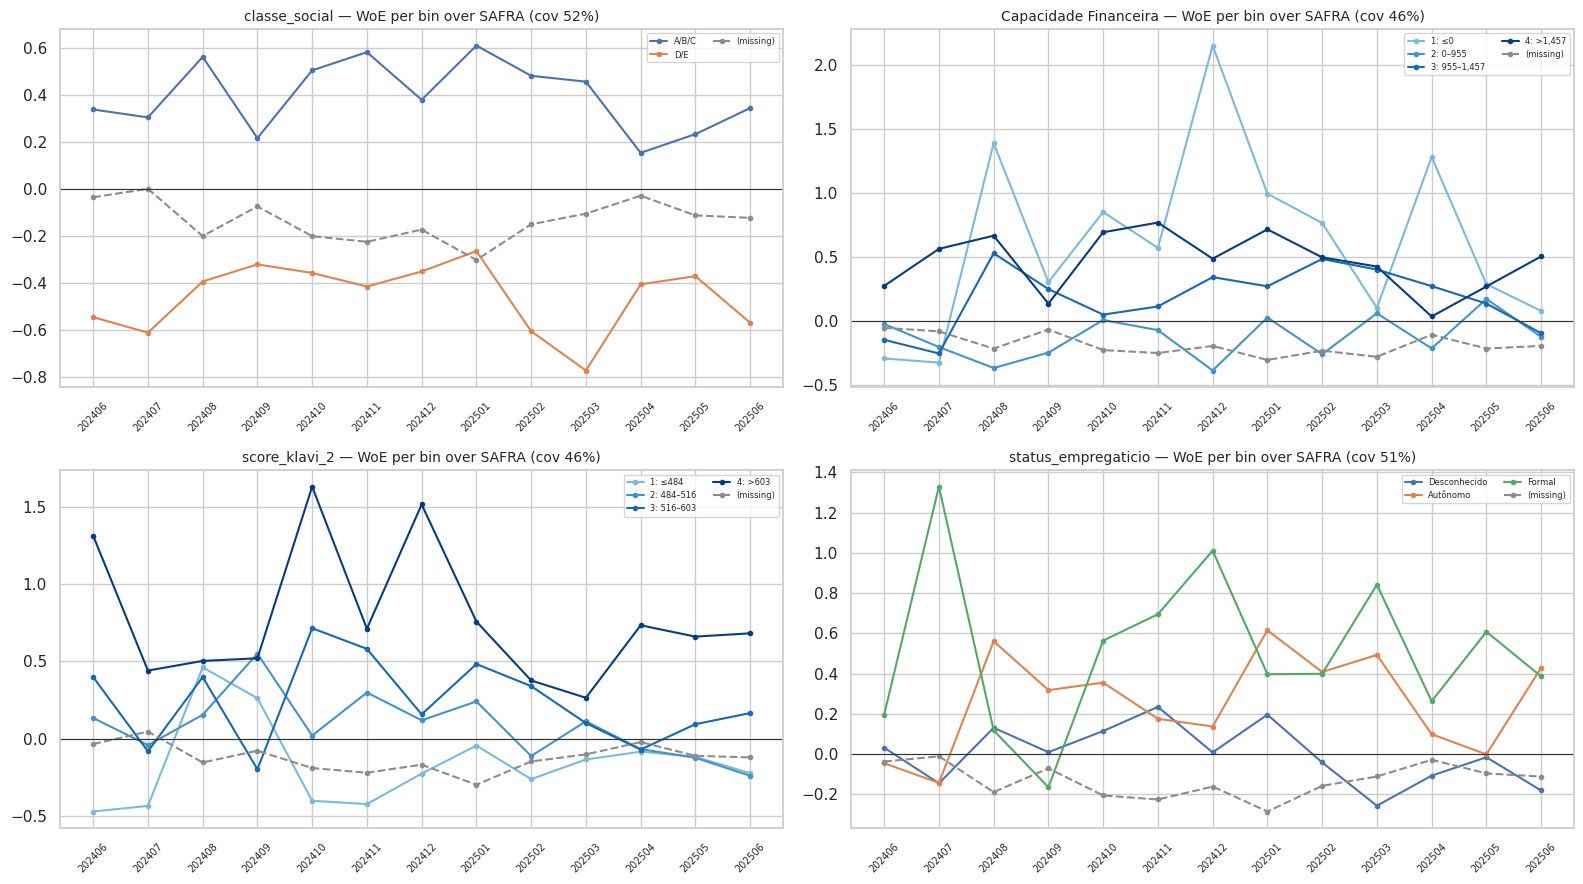

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))    # landscape, fits a 16:9 slide
for ax, v in zip(axes.flat, plot_order):           # same IV-descending order as §5
    wt = woe.woe_over_time(binned[v], y, lab["SAFRA"])
    value_bins = [b for b in wt.columns if b != "(missing)"]
    if spec[v]["type"] == "numeric":
        palette = dict(zip(value_bins, plt.cm.Blues(np.linspace(0.45, 0.95, len(value_bins)))))
    else:
        palette = dict(zip(value_bins, sns.color_palette("deep", len(value_bins))))
    for b in value_bins:
        ax.plot(wt.index, wt[b], marker="o", ms=3, lw=1.5, color=palette[b], label=str(b))
    if "(missing)" in wt.columns:
        ax.plot(wt.index, wt["(missing)"], ls="--", marker="o", ms=3, lw=1.5,
                color=COLOR_MISS, label="(missing)")
    ax.axhline(0, color="0.2", lw=0.8)
    ax.set_title(f"{v} — WoE per bin over SAFRA (cov {lab[v].notna().mean():.0%})", fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.legend(fontsize=6, ncols=2)
plt.tight_layout()
plt.show()

## 7. The tuning loop

1. Read §4 (exact WoE table), §5 (discrimination) and §6 (stability) together.
2. Open **`references/bin_spec.yaml`** and merge adjacent bins:
   - **numeric** — delete a value from `cuts` (N cuts → N+1 bins); the two bins on either side of
     that cut fuse.
   - **categorical** — move categories so two of them share one list under `groups`; the group
     order is the plot order. Categories you remove from every group fall into `(outros)`.
3. Re-run **§3–§6** and look again. Repeat until each kept variable is stable over SAFRA *and*
   discriminating.
4. The finished `bin_spec.yaml` is consumed as-is by 2.1 (IV ranking / shortlist) and later
   notebooks — no re-estimation needed there.

Leave `REESTIMATE = False`: §2 will not overwrite your edits. Only flip it if you want to throw
away the current spec and start from fresh quantile cuts.